<a href="https://colab.research.google.com/github/santiagodie/satellite-image-classifier/blob/main/E2_Principal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SANTIAGO DIE MOREJÓN - 20/04/2026 - IA - Entregable 2 - Principal

# Notebook 1: Principal
Este notebook cubre los 5 puntos obligatorios que se piden para el entregable 2.

## 0. Carga de Librerias
Comenzamos instalando y cargando las librerías que vamos a necesitar en esta entregable. La librería `fastai` nos proporciona los distintos algoritmos de aprendizaje profundo y la librería os la utilizamos para la gestión de ficheros.

In [1]:
!pip install fastai -Uq
from fastai.vision.all import *
import os
from google.colab import files
from sklearn.model_selection import train_test_split
import shutil

## 1. Carga de datos
El dataset que escogi para este entregable es el de [Satellite Image Classification](https://www.kaggle.com/datasets/mahmoudreda55/satellite-image-classification?select=data)

Cargamos los ficheros desde el repositorio público de GitHub que habia creado para el entregable 1 donde subi el datasets para este entregable DATA_URL

In [2]:
!wget DATA_URL -O archive.zip
!unzip -q archive.zip

--2026-04-20 17:25:20--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22836290 (22M) [application/zip]
Saving to: ‘archive.zip’

archive.zip         100%[===================>]  21.78M  --.-KB/s    in 0.1s    

2026-04-20 17:25:21 (152 MB/s) - ‘archive.zip’ saved [22836290/22836290]



## 2. Separacion del dataset en Train y Test
El zip solo tiene una carpeta  por clase (sin train/test), hay que partir manualmente igual que en el notebook de instrucciones.

In [3]:
os.makedirs('/content/data/satellite/train', exist_ok=True)
os.makedirs('/content/data/satellite/test', exist_ok=True)

for c in ['cloudy', 'desert', 'green_area', 'water']:
    os.makedirs(f'/content/data/satellite/train/{c}', exist_ok=True)
    os.makedirs(f'/content/data/satellite/test/{c}', exist_ok=True)

In [4]:
path = Path('/content/data')

Vamos ejecutar la siguiente celda para eliminar imagenes que tengan un formato que no pueda ser abierto por la librería.

In [5]:
for im in verify_images(get_image_files('/content/data')):
    os.remove(str(im))

In [6]:
from sklearn.model_selection import train_test_split

trainCloudy,   testCloudy   = train_test_split(get_image_files(path/'cloudy'),    test_size=0.2, random_state=15)
trainDesert,   testDesert   = train_test_split(get_image_files(path/'desert'),    test_size=0.2, random_state=15)
trainGreen,    testGreen    = train_test_split(get_image_files(path/'green_area'),test_size=0.2, random_state=15)
trainWater,    testWater    = train_test_split(get_image_files(path/'water'),     test_size=0.2, random_state=15)

In [7]:
for x in trainCloudy:
    shutil.move(str(x), path/('satellite/train/cloudy/'+x.name))

for x in trainDesert:
    shutil.move(str(x), path/('satellite/train/desert/'+x.name))

for x in trainGreen:
    shutil.move(str(x), path/('satellite/train/green_area/'+x.name))

for x in trainWater:
    shutil.move(str(x), path/('satellite/train/water/'+x.name))


In [8]:
for x in testCloudy:
    shutil.move(str(x), path/('satellite/test/cloudy/'+x.name))

for x in testDesert:
    shutil.move(str(x), path/('satellite/test/desert/'+x.name))

for x in testGreen:
    shutil.move(str(x), path/('satellite/test/green_area/'+x.name))

for x in testWater:
    shutil.move(str(x), path/('satellite/test/water/'+x.name))

In [9]:
shutil.rmtree(path/'cloudy')
shutil.rmtree(path/'desert')
shutil.rmtree(path/'green_area')
shutil.rmtree(path/'water')

La estructura final de los datos es la siguiente
```
data
└── satellite
    ├── test
    │   ├── cloudy
    │   ├── desert
    │   ├── green_area
    │   └── water
    └── train
        ├── cloudy
        ├── desert
        ├── green_area
        └── water
```

## 3. Datablock



In [10]:
db = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2,seed=42),
    get_y=parent_label,
    item_tfms=Resize(460),
    batch_tfms=aug_transforms(size=224, min_scale=0.75)
)

In [11]:
trainPath = Path('/content/data/satellite')

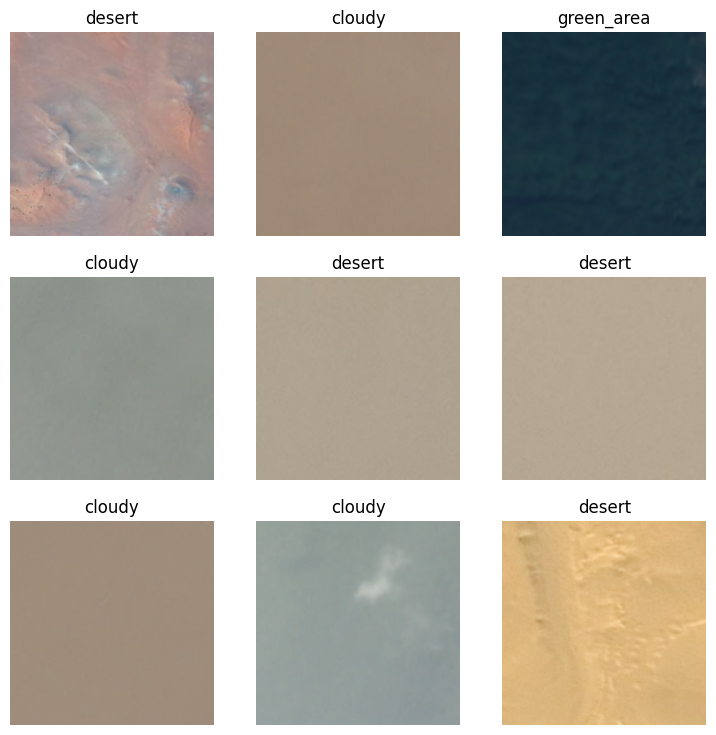

In [12]:
dls = db.dataloaders(trainPath, bs=32)
dls.show_batch()

## 4. Creación del modelo de predicción
A continuación vamos a crear nuestra red convolucional usando transfer learning y utilizando como base la arquitectura ResNet 18

In [13]:
learn = vision_learner(dls, resnet18, metrics=[error_rate, accuracy])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 175MB/s]


In [14]:
learn.fine_tune(5)

epoch,train_loss,valid_loss,error_rate,accuracy,time
0,0.214626,0.054499,0.017762,0.982238,12:33


epoch,train_loss,valid_loss,error_rate,accuracy,time
0,0.093264,0.117389,0.031083,0.968917,18:00
1,0.073702,0.005298,0.001776,0.998224,16:41
2,0.032899,0.000893,0.000000,1.000000,16:28
3,0.025626,0.002230,0.000888,0.999112,16:51
4,0.031245,0.005011,0.001776,0.998224,16:58


En mi caso el entrenamiento se realizo con CPU como entorno de ejecucion.

In [15]:
learn.export('satellite_model.pkl')

In [16]:
Path().ls(file_exts='.pkl')

[Path('export.pkl')]

Vamos a interpretar los resultados utilizando la matriz de confusión

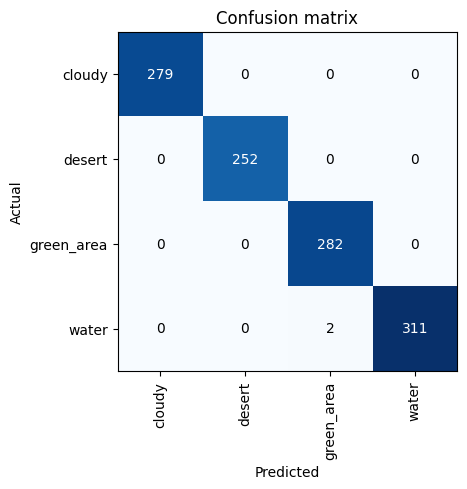

In [17]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

Como vemos en la matriz de confusion el modelo es casi perfecto. Vemos que cometio muy pocos errores
- cloudy: 279/279 bien
- desert: 252/252 bien
- green_area: 282/282 bien
- water: 311/313 bien

## 5. Evaluacion del modelo en el conjunto de test

Para poder evaluar nuestro modelo en el conjunto de test debemos crear un nuevo DataBlock y un nuevo DataLoader.

In [18]:
dbTest = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=GrandparentSplitter(valid_name='test'),
    get_y=parent_label,
    item_tfms=Resize(460),
    batch_tfms=[*aug_transforms(size=224, min_scale=0.75),
                Normalize.from_stats(*imagenet_stats)]
)

En el Datablock de entrenamiento no hacia falta notmalizar los datos ya que `vision_learner` ya añade la normalización ImageNet automáticamente, por que es necesario normalizar en elDatablock de test ya que el modelo espera datos normalizados o nos dara resultados malos.

In [19]:
testPath = Path('/content/data/satellite')

In [20]:
dls_test = dbTest.dataloaders(testPath, bs=32)
learn.dls = dls_test

In [21]:
learn.validate()

[0.007327442988753319, 0.0017746229423210025, 0.9982253909111023]

El método validate nos devuelve dos valores, el valor de la función de pérdida, y el valor de nuestra métrica.

* Resultado antes de normalizar en dbTest
  - 12.93 — valor de la función de pérdida. Alto, indica que el conjunto de validación le cuesta más que el de entrenamiento.
  - 0.688 — error rate (68.8% de errores)
  - 0.312 — accuracy (31.2% de aciertos)
* Resultados despues de normalizar en dbTest
  - 0.007 — loss muy bajo
  - 0.0017 — error rate (0.27% de errores)
  - 0.998 — accuracy (99.7% de aciertos)

## 6. Limpiando el dataset (Adicional)

In [22]:
from fastai.vision.widgets import ImageClassifierCleaner

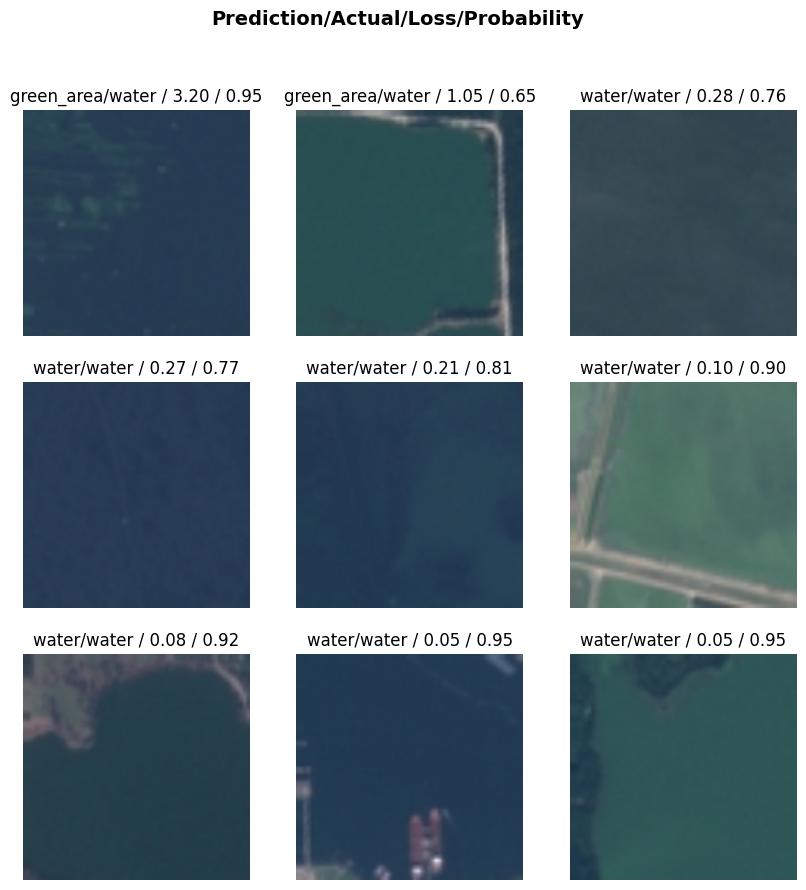

In [23]:
interp.plot_top_losses(9, figsize=(10,10))

Con plot_top_loosses podemos ver las imagenes que ams le costaron predecir al modelo.
* La primera es la imagen con la perdida mas importante ya que el modelo habia predicho con un 100% de confianza que era `water`.
* La segunda y tercera tiene perdidas mucho menores y viendolas es razonable que se haya equivocado
* El resto de imágenes son predicciones correctas con pérdidas muy bajas, pero realizadas con menor confianza que el resto.

In [24]:
learn.dls = dls

Es importante ejecutar `learn.dls = dls` porque de lo contrario estaremos limpiando el split de split de test y no el de entrenamiento

In [25]:
from fastai.vision.widgets import ImageClassifierCleaner
cleaner = ImageClassifierCleaner(learn)
cleaner

In [26]:
eliminadas_total = []

In [27]:
nuevas = [str(cleaner.fns[idx]) for idx in cleaner.delete()]
eliminadas_total += nuevas
for fns in cleaner.delete():
    cleaner.fns[fns].unlink()

In [28]:
print(len(eliminadas_total))

0


In [29]:
for img in eliminadas_total:
    print(img)

Despues de limpiar tenemos que volver a ejecutarlas celdas del db y dls ya que sino seguiran apuntando a ficheros ya eliminados

In [34]:
db = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2,seed=42),
    get_y=parent_label,
    item_tfms=Resize(460),
    batch_tfms=aug_transforms(size=224, min_scale=0.75)
)

In [35]:
dls = db.dataloaders(trainPath, bs=32)

## 7. Usando el modelo

Vamos a usar el modelo ante una nueva imagen. Para ello lo primero que vamos a hacer es cargar el modelo.

In [47]:
!wget DATA_URL -O satellite_model.pkl

--2026-04-20 19:20:46--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 47081990 (45M) [application/octet-stream]
Saving to: ‘satellite_model.pkl’

satellite_model.pkl 100%[===================>]  44.90M   159MB/s    in 0.3s    

2026-04-20 19:20:47 (159 MB/s) - ‘satellite_model.pkl’ saved [47081990/47081990]



In [48]:
learn_inf = load_learner('satellite_model.pkl')

Las fotos las obtuve de Google Earth, salvo nubes-satelite que es de google. Vamos a predecir a que clase pertenecen usando el modelo que entrenamos

In [49]:
!wget DATA_URL
!wget DATA_URL
!wget DATA_URL
!wget DATA_URL
!wget DATA_URL

--2026-04-20 19:20:52--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1011304 (988K) [image/png]
Saving to: ‘Galapagos-green.png.1’

Galapagos-green.png 100%[===================>] 987.60K  --.-KB/s    in 0.05s   

2026-04-20 19:20:52 (18.2 MB/s) - ‘Galapagos-green.png.1’ saved [1011304/1011304]

--2026-04-20 19:20:52--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1032428 (1008K) [image/png]
Saving to: ‘Galapagos-water.png.1’

Galapagos-water.png 100%[===================>]   1008K  --.-KB/s    in 0.05s   



In [50]:
import PIL.Image

predicción=desert | esperada=green_area | confianza=86.78%


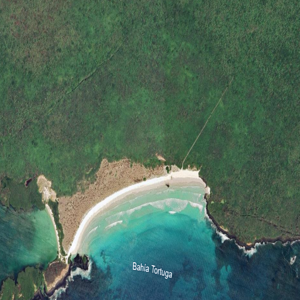

In [51]:
name, esperada = 'Galapagos-green.png', 'green_area'
img = PILImage.create(name)
pred, idx, probs = learn_inf.predict(img)
print(f"predicción={pred} | esperada={esperada} | confianza={max(probs):.2%}")
display(PIL.Image.open(name).resize((300, 300)))

predicción=desert | esperada=water | confianza=50.74%


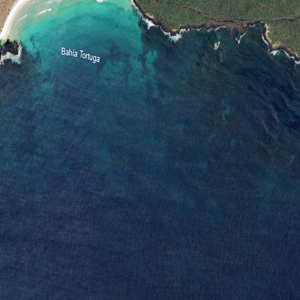

In [52]:
name, esperada = 'Galapagos-water.png', 'water'
img = PILImage.create(name)
pred, idx, probs = learn_inf.predict(img)
print(f"predicción={pred} | esperada={esperada} | confianza={max(probs):.2%}")
display(PIL.Image.open(name).resize((300, 300)))

predicción=desert | esperada=desert | confianza=100.00%


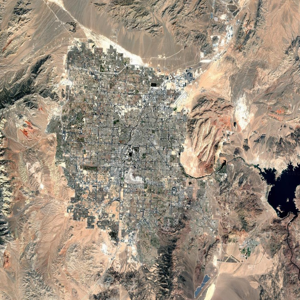

In [53]:
name, esperada = 'Vegas.png', 'desert'
img = PILImage.create(name)
pred, idx, probs = learn_inf.predict(img)
print(f"predicción={pred} | esperada={esperada} | confianza={max(probs):.2%}")
display(PIL.Image.open(name).resize((300, 300)))

predicción=desert | esperada=desert | confianza=59.22%


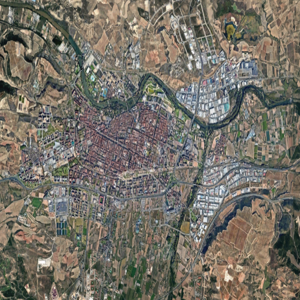

In [54]:
name, esperada = 'logroño_satelite.png', 'desert'
img = PILImage.create(name)
pred, idx, probs = learn_inf.predict(img)
print(f"predicción={pred} | esperada={esperada} | confianza={max(probs):.2%}")
display(PIL.Image.open(name).resize((300, 300)))

predicción=desert | esperada=cloudy | confianza=99.91%


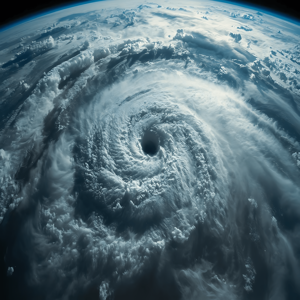

In [55]:
name, esperada = 'nubes-satelite.png', 'cloudy'
img = PILImage.create(name)
pred, idx, probs = learn_inf.predict(img)
print(f"predicción={pred} | esperada={esperada} | confianza={max(probs):.2%}")
display(PIL.Image.open(name).resize((300, 300)))

A pesar de que las imágenes son visualmente claras nosotros, el modelo falla en la mayoría de casos.Esto se puede deber a varios factores

- Las imágenes del dataset son de un satélite específico con una paleta de colores y resolución particular. Las imágenes de prueba son de Google Earth, con estética muy diferente.
- Logroño es una ciudad, categoría que no existe en el dataset.
  
Esta test de imagenes nos muestra que el modelo funciona muy bien dentro del dataset pero no generaliza a imagenes de otras fuentes.

## 8. Creando una aplicación para nuestro modelo

In [45]:
!pip install huggingface_hub["fastai"] -Uq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.5/645.5 kB 12.0 MB/s eta 0:00:00


In [46]:
from huggingface_hub import notebook_login

notebook_login()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [57]:
from huggingface_hub import push_to_hub_fastai

# repo_id = "YOUR_USERNAME/YOUR_LEARNER_NAME"
repo_id = "santiagodie/satellite"

push_to_hub_fastai(learner=learn, repo_id=repo_id)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...die27/satellite/model.pkl:   5%|4         | 2.26MB / 47.0MB            

CommitInfo(commit_url='https://huggingface.co/santiagodie/satellite/commit/8490a8e4936e4f926420943dd33d9aad0efb3110', commit_message='Push FastAI model using huggingface_hub.', commit_description='', oid='8490a8e4936e4f926420943dd33d9aad0efb3110', pr_url=None, repo_url=RepoUrl('https://huggingface.co/santiagodie/satellite', endpoint='https://huggingface.co', repo_type='model', repo_id='santiagodie/satellite'), pr_revision=None, pr_num=None)

En HuggingFace he creado la siguiente [aplicacion](https://huggingface.co/spaces/santiagodie/Entregable2/tree/main) y la [interfaz](https://santiagodie-entregable2.hf.space/?__theme=system&deep_link=LfPvFoLv6TM) que se genera es la siguiente.